...................................................................<br>
<br>
                  HOMEWORK PROJECT (2026)                          <br>
                                                                   <br>
+ M2/IMAPP/DU : Advanced Statistics                                <br>
+ author      : O.Deschamps (odescham@in2p3.fr)                    <br>
+ date        : 2026/10/11                                         <br>
<br>
+ compliant with python 3.9<br>
<br>
...................................................................


==================================================================<br>
 <br>
        Did Ehrenfest's dog meet Schrödinger's cat ?                 <br>
 <br>
================================================================== 


In [1]:
import sys
import math
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
import scipy.stats as stats
from scipy.optimize import minimize
import scipy.special
from scipy.optimize import curve_fit
import unicodedata
from tqdm import trange  ## Display a progression bar (if tqdm module can not be installed replace 'trange' with 'range' in the code)


 ===============================================================<br>
   ====================== GLOBAL SETTINGS ==========================<br>
  ===================================================================<br>


In [2]:
np.random.seed(54321)          # Random seed for reproducibility (remove it to start a different random sequence each run)
dim_sys=[6,8,10,12,14,16,18]   # The dimensions of the system (even numbers only)
num_exp=500                    # Number of repeated trips (for averaging)
max_flips=int(1e7)             # Maximal number of flips (to protect against very long trips)
max_hist_entries=int(1e5)      # Maximal number of entries in histograms to avoid large memory load


 ==============================================================<br>
   ========================= CAUTION ==============================<br>
  ==================================================================<br>
    The processing time rapidly explodes with the system dimension N <br>
     for N + 2 ==> processing times slow down by factor ~4.          <br>
    With the current settings the processing time is <10mn on my PC <br>
                                                                    <br>
  ! Reduce num_exp and/or remove higher dimension(s) if too slow   <br>
  ! Conversely you can upgrade the settings to gain in precision     <br>
                                                                    <br>
   NOTE : 'trange' function requires 'tqdm' python module           <br>
  !        if it cannot be installed replace 'trange' with 'range' in the code   <br>
=================================================================  



 ++++++++++++++++++++++++++++++++++++++++++<br>
  The system consists in N bistate elements <br>
  ========= SYSTEM INITIAL STATE ===========<br>
      (all fleas are on the same dog)      <br>
  N+ = N   and  N-  = N - N+ = 0               <br>
  Initial asymmetry A = [N+  - N- ]/N = +1  <br>
+++++++++++++++++++++++++++++++++++++=+++ 


In [3]:
def init_state(N) :
    istate=1                                # initial elements state
    state=[istate for _ in range(N)]
    return state


 +++++++++++++++++++++++++++++++++++++++++<br>
    Random flip of one system element   <br>
    (one flea is jumping on another dog)   <br>
    A single flip define the 'time unit'    <br>
+++++++++++++++++++++++++++++++++++++++++ 


In [4]:
def flip_state(state,N) :
    idx=np.random.choice(N)              # one (random) element flips state
    state[idx]=-1*state[idx]             # +1 <==> -1 
    return state


 ++++++++++++++++++++++++++++++++++++++++++++++++++++++++<br>
    Round trip : from initial state to initial state   <br>
     (fleas are jumping until the system is back to its      <br>
      initial asymmetrical state .. or max_flips is reached) <br>
    Collect observables                                     <br>
     ++ number of flips to complete the round trip         <br>
     ++ number of flips before 1st visit to equilibrium    <br>
     ++ average <flips> between two visits to equilibrium  <br>
     ++ asymmetry data A=[N+ - N- ] / N                    <br>
+++++++++++++++++++++++++++++++++++++++++++++++++++++++ 


In [5]:
def run_trip(N) :
    if N%2 == 1 :
        print('\n Stop: Odd system dimensions '+str(N)+' are not allowed')
        exit()
    state=init_state(N)  # create the initial state
    istate=state[0] 
    # === define the observables 
    back_init=0   # number of flips before the system returns to its initial state (i.e.: one round trip)
    first_eq=0    # number of flips before first visit to equilibrium (i.e. asymmetry A=0)
    last_eq=0     # last visit to equilibrium 
    count_eq=0    # number of visits to equilibrium
    go=True
    iflip=0
    asys=[]   # collect asymmetries data
    while go and max_flips>iflip :
        iflip=iflip+1
        flip_state(state,N) # +++ single-flip : one (random) flea jumps
        asy=sum(state)/N      # system asymmetry A=[N+ - N-]/N
        asys.append(asy)
        if  asy == 0 :          # dimension is even -> equilibrium if reached when asymmetry A = 0
            last_eq=iflip
            count_eq=count_eq+1
            if first_eq == 0 :  first_eq=iflip
        elif asy == istate :       # back to initial state
            go=False               # stop the sequence
            if back_init == 0 : back_init=iflip
            # allow multiple round trips for the low dimensions (=4) to ensure several visits to equilibrium           
            if N ==4  and iflip < 1000 : go=True
        elif iflip==max_flips :   # hitting max_flips (take care - this should never occur - increase value or reduce dimension if needed)
            go=False
            print('... Warning: max_flips is reached !')
    
    delta_eq=0
    if count_eq > 1 :
        delta_eq=(last_eq-first_eq)/(count_eq-1) # average time between two visits to equilibrium
    return back_init,first_eq,delta_eq,asys


 ++++++++++++++++++++++++++++++++++++++++<br>
    Plot observable average (yy,eyy) as a  <br>
     function of the system dimension (xx) <br>
    Add 2-params fit-function (fun)     <br>
+++++++++++++++++++++++++++++++++++++++ 


In [6]:
def fun_plot(name,xx,yy,eyy,fun=None,p_init=[1.,0.],ylabel='',dfun=None) :
    fig=plt.figure(name)
    plt.errorbar(xx, yy, fmt='o', yerr=eyy)
    plt.grid()
    plt.title(name+' as a function of N')
    plt.xlabel('System dimension (N)')
    plt.ylabel(ylabel)
    plt.draw()
    par=None
    cov=None
    cor=0
    if fun != None :
        par,cov = curve_fit(fun, xx, ydata=yy,sigma=eyy,p0=p_init,absolute_sigma=True)
        xs = np.linspace(xx[0]-0.5,xx[len(xx)-1]+0.5,100)
        ys = fun(xs,par[0],par[1])
        plt.plot(xs, ys)

        # == Print fit parameters & correlation
        a=par[0]
        ea=math.sqrt(cov[0,0])
        b=par[1]
        eb=math.sqrt(cov[1,1])
        cor=cov[0,1]/math.sqrt(cov[0,0]*cov[1,1])
        print(" ++++++++++++++++++++++++++++++++++++++++")
        print(' ++++ ',name)
        print(" ++++++++++++++++++++++++++++++++++++++++")
        if not dfun == None : print(' + Fit-function : '+ylabel+' = ['+dfun+']')
        print(' + Least squares results (curve_fit method)')
        par_print(' + parameter a =',a,ea)
        par_print(' + parameter b =',b,eb)
        print(' + correlation  %5.4f'  %(cor))   

        # == plt decoration
        dx=(plt.xlim()[1]-plt.xlim()[0])
        dy=(plt.ylim()[1]-plt.ylim()[0])
        xpos=plt.xlim()[0]+dx/3
        ypos=plt.ylim()[1]-dy/10
        if not dfun == None : plt.text(xpos,ypos,'Fit-function : '+ylabel+' = ['+dfun+']')            
        plt.text(xpos,ypos-dy/10  ,'a ='+par2txt(a,ea))
        plt.text(xpos,ypos-2*dy/10,'b ='+par2txt(b,eb))
            
    plt.draw()
    plt.pause(0.1)
#    input("press a key to continue")
    return par, cov
 


 ++++++++++++++++++++++++++++++++++++++++++++<br>
    Evaluate Poisson interval (a la Garwood) <br>
++++++++++++++++++++++++++++++++++++++++++++ 


In [7]:
def PoissonError(h,scale,CL=0.683):
    eh=[]
    a=(1.-CL)/2
    for i in range(len(h)) :
        y=h[i]*scale #entries in bin i
        ey=stats.chi2.ppf(1-a,2*(y+1))/2-y # +dy_high
        if y > 0 :
            ey +=y-stats.chi2.ppf(a,2*y)/2 # +dy_low
            ey /= 2                        # symmetrize
        eh.append(ey/scale)
    return eh


 ++++++++++++++++++++++++++++++++++++++++++++++++<br>
    Produce asymmetry histograms                    <br>
     - gaussian fit to extract the variance         <br>
     - Note: a modified binomial pmf fit would be     <br>
       more relevant to fit the asymmetry            <br>
       defined in the limited range (-1,1)           <br>
++++++++++++++++++++++++++++++++++++++++++++++ 


In [8]:
def asy_hist(splt,data,dim,_xlabel='System Asymmetry',_density=True) :
    data=np.array(data)
    bound=(dim+1)/dim                    # binning boundary
    # == Setup the subplot
    h,bins,_=splt.hist(data,dim+1,range=(-bound,+bound),density=_density)
    splt.set(title=_xlabel+' (N= '+str(dim)+')')
    splt.set(xlabel=_xlabel)
    if _density : splt.set(ylabel='density')
    else : splt.set(ylabel='events/bin')

    # == Perform a Gaussian fit
    model=stats.norm
    wbin=(bins[1]-bins[0])            # bin width
    histox= 0.5*(bins[1:]+bins[:-1])  # bins center
    hnorm =1
    if _density : hnorm=len(data)*wbin
    sigmas=PoissonError(h,hnorm)      # evaluate the (poissonian) uncertainties
    pars, cov = curve_fit(lambda data, _mu,_sigma,_norm : _norm*model.pdf(data,loc=_mu,scale=_sigma),histox,h,sigma=sigmas,p0=[data.mean(),data.std(),len(data)*wbin],method='lm')

    # == Get parameters & superimpose the fit curve
    loc=pars[0]
    scale=pars[1]
    norm=pars[2]
    xx=[histox[0]+(bins[1]-bins[0])*i/100 for i in range(100*dim)]  # finer granularity to superimpose the gaussian function curve
    pdf=norm*model.pdf(xx, loc, scale)                              # define the model pdf for the fitted (loc,scale,norm) values
    splt.plot(xx, pdf,'black',linewidth=2,linestyle="solid")        # add the normalized model PDF to the histogram

    # == subplot decoration
    splt.grid(True,axis='x')
    ypos=splt.get_ylim()[1]
    splt.set(ylim=(0.,ypos*1.1))
    splt.text(-1.15,ypos*1.02,'Gaussian fit:')
    splt.text(-1.15,ypos*0.92,greek('mu')+'='+par2txt(loc,math.sqrt(cov[0][0])))
    splt.text(-1.15,ypos*0.82,greek('sigma')+'='+par2txt(scale,math.sqrt(cov[1][1])))
    return pars,cov,sum(h)*wbin


 ++++++++++++++++++++++++++++++++++++++++++++++++++<br>
   Produce histograms of number of flips (semilog)  <br>
++++++++++++++++++++++++++++++++++++++++++++++++ 


In [9]:
def obs_hist(splt,data,dim,_xlabel='flips') :
    # == Setup the subplot
    splt.set(title=_xlabel+' (N= '+str(dim)+')')
    splt.set(xlabel='number of flips')
    splt.set(ylabel='events/bin')
    xmax=int(np.max(data))
    xmin=int(np.min(data))
    bins=min(100,xmax+1)
    splt.hist(data,bins,range=(xmin-0.5,xmax+0.5))

    # == Get sample mean and associated error
    hmean=data.mean()
    hmerr=data.std()/math.sqrt(len(data))

    # == decoration
    splt.grid(True,axis='x')
    xpos=splt.get_xlim()[0]+(splt.get_xlim()[1]-splt.get_xlim()[0])/6
    ypos=splt.get_ylim()[1]*1.5
    splt.semilogy()
    splt.set_ylim(0.8,ypos*1.5)
    splt.text(xpos,ypos,'<mean> = '+par2txt(hmean,hmerr,'%4.2f'))
    return hmean,hmerr


 +++++++++++++++++++++++++++++++++<br>
   Display 2D ellipse error area    <br>
+++++++++++++++++++++++++++++++ 


In [10]:
def par_plot(name,par,cov,theo,CL=0.95,fcol='red',idx=[0,1],**kwargs):
    w,eig=np.linalg.eig(cov)
    l=[math.sqrt(v) for v in w]
    u=par[0]    #x-position of the center
    v=par[1]    #y-position of the center
    scale=math.sqrt(stats.chi2.ppf(CL,2))
    l=[math.sqrt(v) for v in w]
    a=2*scale*l[0]        #2*radius on the x-axis
    b=2*scale*l[1]        #2*radius on the y-axis
    th=0.5*math.atan(2*cov[0,1]/(cov[0,0]-cov[1,1]))*180./math.acos(-1)
    e=Ellipse([u,v], a, b ,angle=th , facecolor=fcol,edgecolor='black',**kwargs)
    fig = plt.figure(name)
    ax = fig.add_subplot(111)    
    ax.set(title='2D area : '+str(CL*100)+' % Confidence Level')
    eu=math.sqrt(cov[0,0])
    ev=math.sqrt(cov[1,1])
    nu=max(3,int(abs(u-theo[0])/eu+0.5))
    nv=max(3,int(abs(v-theo[1])/ev+0.5))
    ax.set_xlim(u-nu*eu,u+nu*eu)
    ax.set_ylim(v-nv*ev,v+nv*ev)
    ax.add_patch(e)
    plt.axhline(y=theo[1], color='blue', linestyle='dotted')
    plt.axvline(x=theo[0], color='blue', linestyle='dotted')
    plt.text(u+eu,theo[1]+ev/20,'Expected')
    plt.axhline(y=v, color='black', linestyle='solid')
    plt.axvline(x=u, color='black', linestyle='solid')
    plt.text(u+eu,v+ev/20,'Observed')
    ax.set(xlabel=r'$\hat{a}$')
    ax.set(ylabel=r'$\hat{b}$')
    plt.draw()
    plt.pause(0.1)
#    input("press a key to continue")


 ++++++++++++++++++<br>
    Printout helpers  <br>
  ++++++++++++++++++ 
 

In [11]:
def greek(c)                      : return unicodedata.lookup("GREEK SMALL LETTER "+str(c))
def par2txt(par,err,form='%5.3f') : return str(format(form %(par)))+' ± '+str(format(form %(err)))
def par_print(desc,par,err,fdef='',vdef=None,form='%5.3f') :
    txt=desc+' '+par2txt(par,err,form)
    if not vdef == None :
        txt=txt+'  --- '+fdef+' = ['+form+']'
        print(txt %(vdef))
    else :
        print(txt)
    return        


 +++++++++++++++++++++++++++++++++++++++++ <br>
 ++++++++++++++++++++++++++++++++++++++++++++ <br>
                                              <br>
         THE MAIN PROCESSING                  <br>
                                              <br>
 + Process num_exp repetitions of round trips <br>
 + Collect observables means and errors       <br>
   for the different system dimensions        <br>
                                              <br>
 ++++++++++++++++++++++++++++++++++++++++++++ <br>
+++++++++++++++++++++++++++++++++++++++ 


In [12]:
nsys=len(dim_sys)  # number of tested dimensions
o0_mean=[0 for _ in range(nsys)]
o0_err=[0  for _ in range(nsys)]
o1_mean=[0 for _ in range(nsys)]
o1_err=[0  for _ in range(nsys)]
o2_mean=[0 for _ in range(nsys)]
o2_err=[0  for _ in range(nsys)]
o3_mean=[0 for _ in range(nsys)]
o3_err=[0  for _ in range(nsys)]
iexp=0

 +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
 +++ Processing  500  round trips - system dimension N= 6  ... be patient ...
 +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 500/500 [00:00<00:00, 2809.81it/s]


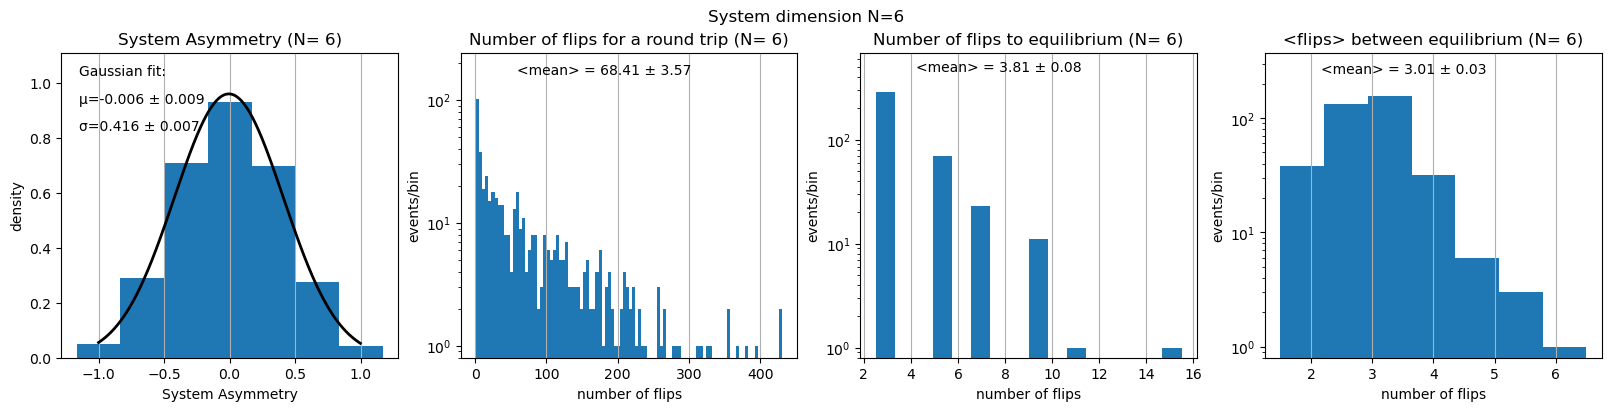

 ++ Asymmetry mean (N=6): μ =  -0.006 ± 0.009  ---  expect  = [0.000]
 ++ Asymmetry rms  (N=6): σ =  0.416 ± 0.007  ---  theory [1/sqrt(N)] = [0.408]
 ++ Asymmetry norm (N=6): I =  1.002 ± 0.021  ---  expect ~ = [1.000]
 ++ Average round trip duration       : <flips> = 68.4 ±  3.6  --- theory [2^N] = [64.0]
 ++ Average time to 1st equilibrium   : <flips> = 3.807 ± 0.080
 ++ Average time between equilibrium  : <flips> = 3.008 ± 0.034  --- theory [2^N/binomial(N,N/2)] = [3.200]
 +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
 +++ Processing  500  round trips - system dimension N= 8  ... be patient ...
 +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 500/500 [00:00<00:00, 762.80it/s]


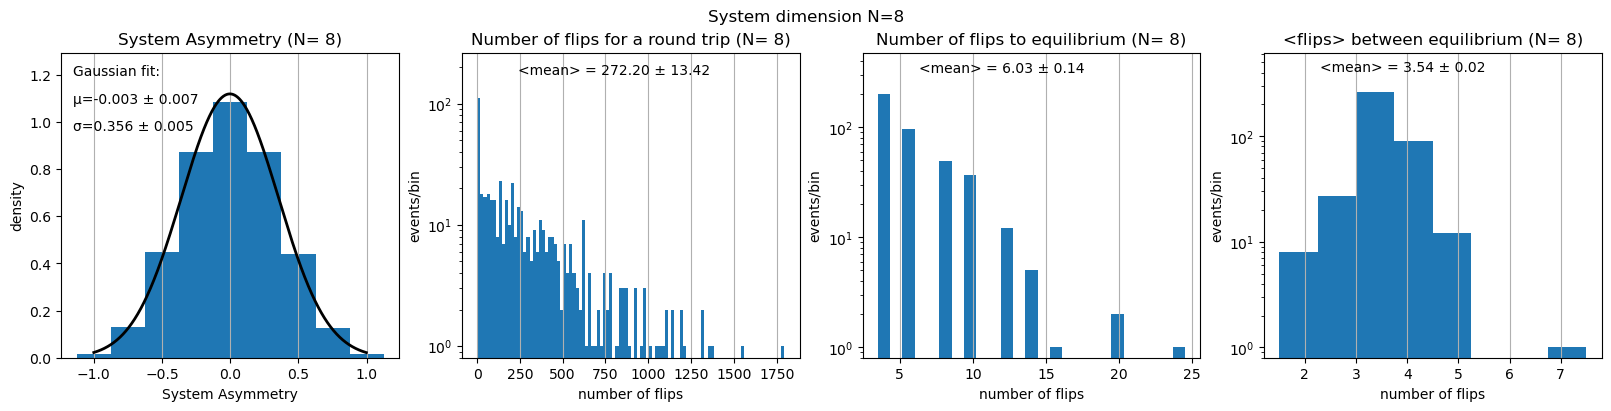

 ++ Asymmetry mean (N=8): μ =  -0.003 ± 0.007  ---  expect  = [0.000]
 ++ Asymmetry rms  (N=8): σ =  0.356 ± 0.005  ---  theory [1/sqrt(N)] = [0.354]
 ++ Asymmetry norm (N=8): I =  0.999 ± 0.020  ---  expect ~ = [1.000]
 ++ Average round trip duration       : <flips> = 272.2 ± 13.4  --- theory [2^N] = [256.0]
 ++ Average time to 1st equilibrium   : <flips> = 6.035 ± 0.139
 ++ Average time between equilibrium  : <flips> = 3.536 ± 0.025  --- theory [2^N/binomial(N,N/2)] = [3.657]
 +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
 +++ Processing  500  round trips - system dimension N= 10  ... be patient ...
 +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 500/500 [00:02<00:00, 197.51it/s]


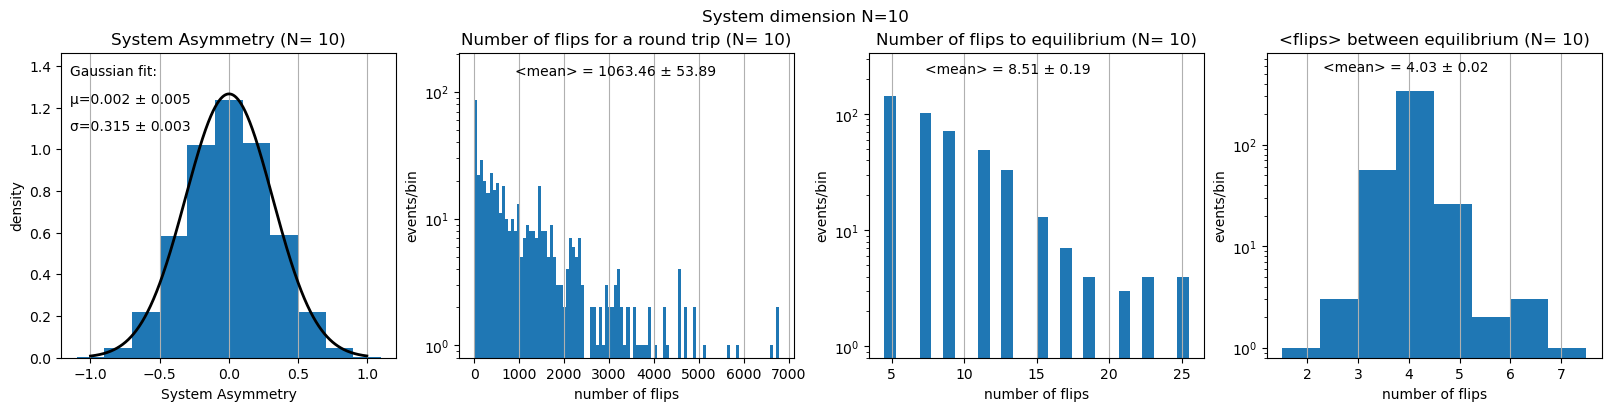

 ++ Asymmetry mean (N=10): μ =  0.002 ± 0.005  ---  expect  = [0.000]
 ++ Asymmetry rms  (N=10): σ =  0.315 ± 0.003  ---  theory [1/sqrt(N)] = [0.316]
 ++ Asymmetry norm (N=10): I =  0.999 ± 0.015  ---  expect ~ = [1.000]
 ++ Average round trip duration       : <flips> = 1063.5 ± 53.9  --- theory [2^N] = [1024.0]
 ++ Average time to 1st equilibrium   : <flips> = 8.509 ± 0.192
 ++ Average time between equilibrium  : <flips> = 4.032 ± 0.020  --- theory [2^N/binomial(N,N/2)] = [4.063]
 +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
 +++ Processing  500  round trips - system dimension N= 12  ... be patient ...
 +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 500/500 [00:09<00:00, 51.54it/s]


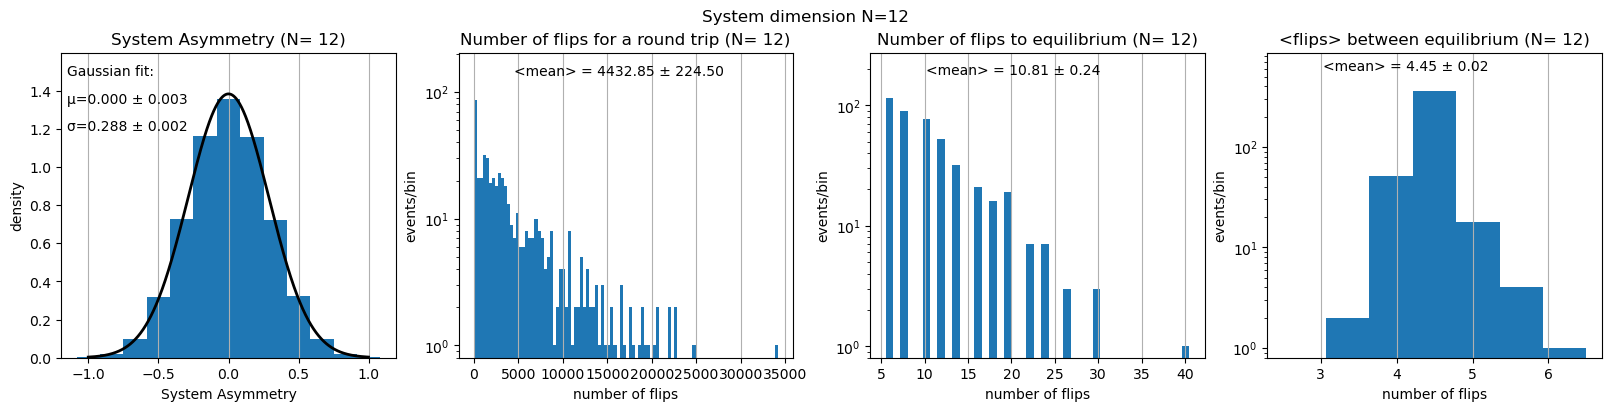

 ++ Asymmetry mean (N=12): μ =  0.000 ± 0.003  ---  expect  = [0.000]
 ++ Asymmetry rms  (N=12): σ =  0.288 ± 0.002  ---  theory [1/sqrt(N)] = [0.289]
 ++ Asymmetry norm (N=12): I =  0.999 ± 0.012  ---  expect ~ = [1.000]
 ++ Average round trip duration       : <flips> = 4432.8 ± 224.5  --- theory [2^N] = [4096.0]
 ++ Average time to 1st equilibrium   : <flips> = 10.810 ± 0.243
 ++ Average time between equilibrium  : <flips> = 4.445 ± 0.015  --- theory [2^N/binomial(N,N/2)] = [4.433]
 +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
 +++ Processing  500  round trips - system dimension N= 14  ... be patient ...
 +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 500/500 [00:35<00:00, 14.25it/s]


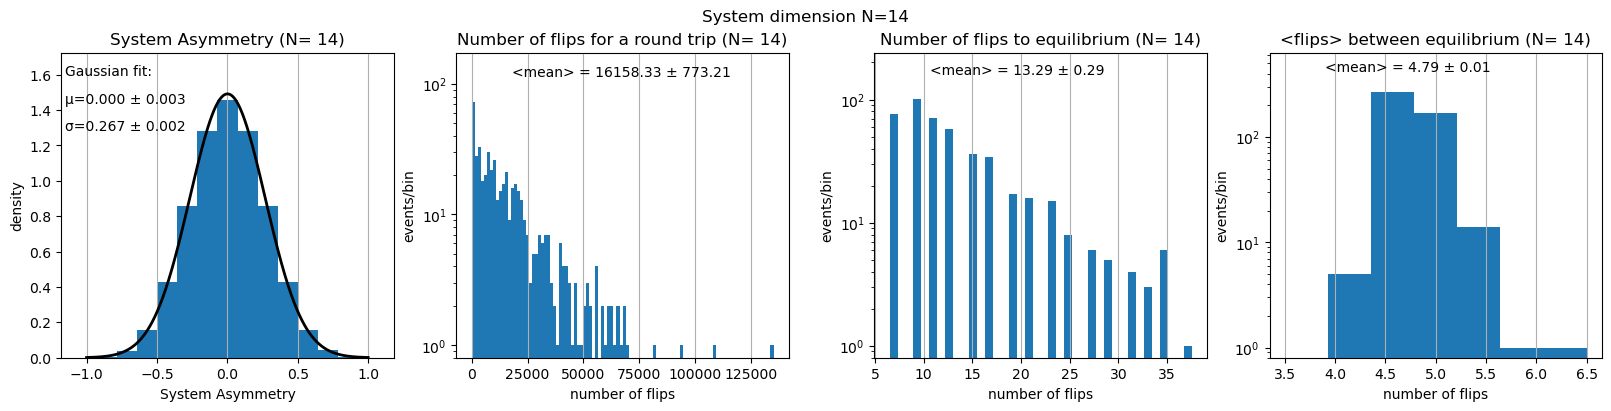

 ++ Asymmetry mean (N=14): μ =  0.000 ± 0.003  ---  expect  = [0.000]
 ++ Asymmetry rms  (N=14): σ =  0.267 ± 0.002  ---  theory [1/sqrt(N)] = [0.267]
 ++ Asymmetry norm (N=14): I =  0.999 ± 0.011  ---  expect ~ = [1.000]
 ++ Average round trip duration       : <flips> = 16158.3 ± 773.2  --- theory [2^N] = [16384.0]
 ++ Average time to 1st equilibrium   : <flips> = 13.293 ± 0.294
 ++ Average time between equilibrium  : <flips> = 4.786 ± 0.010  --- theory [2^N/binomial(N,N/2)] = [4.774]
 +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
 +++ Processing  500  round trips - system dimension N= 16  ... be patient ...
 +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████▊| 499/500 [02:26<00:00,  2.28it/s]

In [ ]:
for N in dim_sys : # ++ loop over the (nsys) system dimensions
    print(" +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++")
    print(" +++ Processing ",num_exp," round trips - system dimension N=",N," ... be patient ...")
    print(" +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++")
    tup=[run_trip(N) for _ in trange(num_exp)]     # THE MAIN LOOP ++ repeat (num_exp) round trips and collect all data as tuple

    # Relevant arrays of data
    o0=[]                                            # Accumulate the asymmetry data (can be very large array)   
    for k in range(num_exp) :
        if len(o0) < max_hist_entries : o0.extend(tup[k][3]) # limit the histo entries to avoid large memory load
    o1=np.array([tup[k][0] for k in range(num_exp)]) # obs1 (number of flips for the round trips)
    o2=np.array([tup[k][1] for k in range(num_exp)]) # obs2 (number of flips to 1st visit to equilibrium)
    o3=np.array([tup[k][2] for k in range(num_exp)]) # obs3 (number of flips between two visits to equilibrium)

    # ==== produce Figures
    fig, (oh0,oh1,oh2,oh3) = plt.subplots(1, 4, layout='constrained', figsize=(16, 4))
    fig.suptitle('System dimension N='+str(N))
    pars,cov,hnorm=asy_hist(oh0,o0,N)                                 # produce asymmetries histo
    mo1,eo1=obs_hist(oh1,o1,N,'Number of flips for a round trip')     # produce #flips histos
    mo2,eo2=obs_hist(oh2,o2[o2>0],N,'Number of flips to equilibrium') # (ensure equilibrium is reached at least once)
    mo3,eo3=obs_hist(oh3,o3[o3>0],N,'<flips> between equilibrium')      
    plt.draw()
    plt.pause(0.1)
    
    # ==== Print the results
    par_print(' ++ Asymmetry mean (N='+str(N)+'): '+greek('mu')   +' = ',pars[0],math.sqrt(cov[0][0]),' expect ',0.0)
    par_print(' ++ Asymmetry rms  (N='+str(N)+'): '+greek('sigma')+' = ',pars[1],math.sqrt(cov[1][1]),' theory [1/sqrt(N)]',1/math.sqrt(N))
    par_print(' ++ Asymmetry norm (N='+str(N)+'): I = '     ,pars[2],math.sqrt(cov[2][2]),' expect ~',hnorm)        
    scale=scipy.special.binom(N,math.floor(N/2))  # binomial coefficient (N,N/2)
    par_print(" ++ Average round trip duration       : <flips> =",mo1,eo1,'theory [2^N]',2**N,'%4.1f')
    par_print(" ++ Average time to 1st equilibrium   : <flips> =",mo2,eo2)
    par_print(" ++ Average time between equilibrium  : <flips> =",mo3,eo3,'theory [2^N/binomial(N,N/2)]',2**N/scale)

    # Collect means and corresponding errors as a function of the dimension N
    o0_mean[iexp]=pars[1]                # asymmetry rms
    o0_err[iexp]=math.sqrt(cov[1][1])
    o1_mean[iexp]=mo1                    # mean number of flips for returning to initial state
    o1_err[iexp]=eo1                     
    o2_mean[iexp]=mo2                    # mean number of flips to equilibrium
    o2_err[iexp]=eo2
    o3_mean[iexp]=mo3                    # mean number of flips between two equilibrium
    o3_err[iexp]=eo3
    iexp=iexp+1
    

In [ ]:

''' ++++++++++++++++++++++++++++++++++++++++++++
    ++++++++++++++++++++++++++++++++++++++++++++
              Analysis & Comments
    ++++++++++++++++++++++++++++++++++++++++++++
    ++++++++++++++++++++++++++++++++++++++++++++ '''
input("Press a key to produce the summary plots")   



<br>
I / Studying the average round trips duration as a function of the system dimension<br>
  ------------------------------------------------------------------------------- 


In [ ]:
p,c=fun_plot('I/ Round trip average duration (<flips>) '       ,dim_sys,o1_mean,o1_err,lambda x,a,b : (a*b**x)  ,[1.0,+2.0],'<flips>', '$a * b^{N}$' )


<br>
 + according to the given instructions, the average time for a round trip from/to an initial state defined by N+<br>
   (i.e. an initial asymmetry  A= (2*N+ - N)/N) is the inverse of the binomial probability B(N+ ; N , p=1/2)<br>
 + For a fully asymmetrical initial state N+=N (i.e. asymmetry A=+1) - the expected duration of the round trip<br>
   is then <time> = 2^N<br>
 The parameters returned by the fit function <time> =  a * b^N are fully consistent with the expectation.


In [ ]:
par_plot('Round trip duration as a function of N - fit-function parameters',p,c,(1.0,2.0))


<br>
II / Studying the average time to reach equilibrium as a function of the system dimension<br>
  ------------------------------------------------------------------------------------- 


In [ ]:
p,c=fun_plot('II/ Time to first visit to equilibrium ' ,dim_sys,o2_mean,o2_err,lambda x,a,b : (a*x+b)   ,[1.0,+0.5],'<flips>', '$a * N + b$' )


<br>
 + The minimum number of flips to reach equilibrium from a fully asymmetrical initial state is N/2. The average number<br>
 of flips is of order of N and is relatively well described by a linear fit.



<br>
III / Studying the average time between two visits to equilibrium as a function of the system dimension<br>
  --------------------------------------------------------------------------------------------------- 


In [ ]:
p,c=fun_plot('III/ Time between two equilibrium visits ',dim_sys,o3_mean,o3_err,lambda x,a,b : ((a*x)**b)  ,[1.0,+0.5],'<flips>' , '$(aN)^{b}$' )


<br>
 + for an initial state at equilibrium : N+ = N- = N/2 (i.e. asymmetry A=0) - the expected duration of the trip to the same state<br>
   is : <time> = 1/B(N/2;N,1/2) = 2^N / binomial_coef(N/2,N) . Using Stirling approximation this gives <time> ~ Sqrt(N pi/2)<br>
   as demonstrated in the instructions.<br>
 + The parameters returned by the fit function <time> = (a * N)^b are reasonably consistent with the given expectations (despite<br>
   Stirling formula is not very accurate for the small system dimensions studied here)<br>


<br>
IV / Studying the asymmetry variance as a function of the system dimension <br>
  ---------------------------------------------------------------------- 


In [ ]:
p,c=fun_plot('IV/ Asymmetry RMS '               ,dim_sys,o0_mean,o0_err,lambda x,a,b : (a*x**b)  ,[1.0,-0.5],'RMS', '$a * N^{b}$' )


<br>
+ The quantity N+ defining the current state of the system is expected to be distributed accordng to a binomial<br>
  distribution (N trials and p=1/2).<br>
  The  binomial variance Np(1-p)=N/4 corresponds to an asymmetry variance of 1/N, as demonstrated in the instructions.<br>
+ The asymmetry distribution is fit with a (truncated) Gaussian profile in the (-1,1) range. The sigma evolution as function of N<br>
is fit with a power function 'a * N^b'. The returned a and b parameters are in good agreement with the expectation. 


In [ ]:
par_plot('Asymmetry RMS as a function of N - fit-function parameters',p,c,(1.0,-0.5))


<br>
V / Conclusions<br>
    ------------<br>
 + For an initially asymmetrical system of dimension N=58, if one element flips every second, the average time to reach equilibrium is<br>
   about one minute. Returning to the initial asymmetrical state would take the age of the universe (on average) !<br>
 + Let's Mark Kac to conclude "this is probably one of the most instructive models in the whole of physics." (Kac, 1959)<br>
+++++++++++++++++++ 


In [ ]:
print('THE END')